# 購入履歴から「あなたへのおすすめ」を作る

## 概要

商品が多くても、顧客が欲しいものを見つけられるとは限らない。この記事では、『マーケティングサイエンスの理論と実践』第11章「あなたへのおすすめを作る」を紹介する。選択肢の絞り込みという課題から、協調フィルタリングと行列分解の考え方、Pythonでの推薦リスト作成と評価までを順に扱う。

## 実行環境

カーネルは **wa-src(3.14.6)**、Pythonは **3.14.6** である。使用ライブラリのバージョンは次のセルで表示する。上から順に実行し、図は `11_nb_files` にSVG形式で保存する。データは本書の `doc/02/data/online_retail.csv.gz` を使う。単独で実行する場合は、同じCSVをノートブックと同じ場所に置く。

In [1]:
import platform
from importlib.metadata import version
from pathlib import Path
from pprint import pprint

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from implicit.als import AlternatingLeastSquares
from implicit.bpr import BayesianPersonalizedRanking
from IPython.display import Latex, SVG, display
from matplotlib import font_manager
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, MaxNLocator
from scipy import sparse
from threadpoolctl import threadpool_limits

print(f"環境: wa-src(3.14.6) / Python {platform.python_version()}")
for package in ("numpy", "scipy", "polars", "implicit", "matplotlib", "threadpoolctl"):
    print(f"{package}: {version(package)}")

# ノートブックの保存場所を基準に、画像の出力先を決める。
roots = [Path.cwd(), *Path.cwd().parents]
repo = next((p for p in roots if (p / "doc/11/11_main.tex").exists()), None)
output_dir = repo / "blog/11" if repo else Path.cwd()
image_dir = output_dir / "11_nb_files"
image_dir.mkdir(parents=True, exist_ok=True)
data_path = repo / "doc/02/data/online_retail.csv.gz" if repo else Path.cwd() / "online_retail.csv.gz"

# 表示だけを有効数字3桁にそろえ、計算には丸め前の値を使う。
def sig3(value):
    return format(float(value), "#.3g")

np.set_printoptions(formatter={"float_kind": sig3})
pl.Config.set_tbl_cols(8)
pl.Config.set_tbl_rows(12)
pl.Config.set_fmt_str_lengths(44)

# 日本語フォントがある環境では、日本語のラベルを使う。
available_fonts = {font.name for font in font_manager.fontManager.ttflist}
for font_name in ("Hiragino Sans", "Noto Sans CJK JP", "IPAexGothic", "Yu Gothic"):
    if font_name in available_fonts:
        plt.rcParams["font.family"] = font_name
        break
plt.rcParams.update({"font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "svg.fonttype": "path"})
colors = {"ALS": "#306998", "BPR": "#c27536"}

def show_math(expression):
    # 重要な式の \(...\) を、出力欄で表示数式になる $$...$$ に変換する。
    display(Latex(expression.replace(r"\(", "$$").replace(r"\)", "$$")))

def save_svg(fig, filename):
    """小数の目盛りを有効数字3桁にし、SVGを保存・表示する。"""
    def tick_label(value, position):
        return str(int(value)) if value == int(value) else sig3(value)

    for ax in fig.axes:
        if ax.get_xscale() == "linear":
            ax.xaxis.set_major_formatter(FuncFormatter(tick_label))
        if ax.get_yscale() == "linear":
            ax.yaxis.set_major_formatter(FuncFormatter(tick_label))
    fig.tight_layout()
    destination = image_dir / filename
    fig.savefig(destination, format="svg", bbox_inches="tight")
    plt.close(fig)
    display(SVG(filename=str(destination)))

環境: wa-src(3.14.6) / Python 3.14.6
numpy: 2.5.4
scipy: 1.18.1
polars: 2.1.0
implicit: 0.7.3
matplotlib: 3.11.2
threadpoolctl: 3.8.0


## 1. 選択肢が多いと、なぜ選びにくいのか

本文では、商品数の多いカテゴリで購買転換率が低かった事例から話を始める。ただし、この関係だけで、商品数が原因だとは判断できない。顧客の目的や価格なども関係するためである。

選択肢が増えると判断の負担が増す場合がある。本文は「選択のパラドックス」とヒックの法則を紹介している。選択肢が同程度の確率で選ばれる状況で、候補数$n$と反応時間$T$の関係を次のように表す。$a$は固定の時間、$b$は処理速度に関わる係数である。

In [2]:
show_math(r"\(T=a+b\log_2(n+1)\)")
show_math(r"\(\begin{aligned}"
          r"\frac{T(24)-a}{T(6)-a}"
          r"&=\frac{b\log_2(24+1)}{b\log_2(6+1)}\\"
          r"&=\frac{\log_2 25}{\log_2 7}"
          r"\approx\frac{4.64}{2.81}\approx1.65"
          r"\end{aligned}\)")

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

比較しているのは固定項を除いた部分であり、反応時間全体が1.65倍になるという意味ではない。推薦では、全商品から顧客に合う候補を選び、画面で比較する件数を減らす。私は、モデルを選ぶ前に、何件をどの画面に表示するのかを決めておくことが大切だと考えている。

## 2. 購入履歴を行列にし、推薦スコアを求める

協調フィルタリングは、複数の顧客の購買・評価傾向を利用する方法である。似た顧客や商品を直接探すメモリベースの方法と、履歴からモデルを学習する方法がある。本文は後者の行列分解を扱う。

行を顧客、列を商品とする行列を考える。星評価は明示的フィードバック、購入やクリックは暗黙的フィードバックである。ここでは購入を1、未観測を0とする。0は低評価を意味しない。商品を知らなかった可能性もある。

大部分が未観測のため、記録のある位置と値だけを保存する疎行列を使う。本文と同じ前処理では4,074人、3,145商品、264,510組の購入履歴となる。

In [3]:
show_math(r"\(\mathrm{Density}"
          r"=\frac{264{,}510}{4{,}074\times3{,}145}"
          r"=\frac{264{,}510}{12{,}812{,}730}"
          r"\approx0.0206=2.06\%\)")

<IPython.core.display.Latex object>

行列分解では、顧客と商品を$d$個の潜在因子で表す。顧客のベクトル$\mathbf{p}_u$と商品のベクトル$\mathbf{q}_i$の内積がスコアになる。$\mathbf{P}$、$\mathbf{Q}$はそれらを行に並べた行列である。

In [4]:
show_math(r"\(\widehat{\mathbf{R}}=\mathbf{P}\mathbf{Q}^{\top},\qquad"
          r"\hat r_{ui}=\mathbf{p}_u^{\top}\mathbf{q}_i"
          r"=\sum_{k=1}^{d}p_{uk}q_{ik}\)")
# 学習結果ではなく、内積の計算方法を示す例である。
show_math(r"\(\begin{aligned}"
          r"\mathbf{p}_u&=(0.800,\,0.200)^{\top},\quad"
          r"\mathbf{q}_i=(0.500,\,0.900)^{\top}\\"
          r"\hat r_{ui}&=0.800\times0.500+0.200\times0.900\\"
          r"&=0.400+0.180=0.580"
          r"\end{aligned}\)")

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

潜在因子の各軸に、人が読める意味が付くとは限らない。スコアも購入確率ではなく、同じ顧客に対する商品の順位付けに使う値である。購入済み商品を候補から除き、上位を取り出す。

## 3. ALSとBPRは、何を学習するのか

ALSは、片側の因子を固定して、もう片側を交互に更新する。購入の有無を$r_{ui}$、誤差の重みを$c_{ui}$、正則化係数を$\lambda$とすると、損失は次の式になる。正則化は因子の値が過度に大きくなるのを抑える。

In [5]:
show_math(r"\(\begin{aligned}L_{\mathrm{ALS}}"
          r"&=\sum_{u,i}c_{ui}(r_{ui}-\mathbf{p}_u^{\top}\mathbf{q}_i)^2\\"
          r"&\quad+\lambda\left(\sum_u\|\mathbf{p}_u\|^2"
          r"+\sum_i\|\mathbf{q}_i\|^2\right)\end{aligned}\)")

<IPython.core.display.Latex object>

商品側を固定すると、顧客$u$に関する部分だけを微分できる。勾配を0と置いて項を移すと、更新時に解く連立一次方程式になる。$\mathbf{I}$は単位行列である。顧客側を固定した更新も同じ手順である。

In [6]:
show_math(r"\(\begin{aligned}"
          r"L_u&=\sum_i c_{ui}(r_{ui}-\mathbf{p}_u^{\top}\mathbf{q}_i)^2"
          r"+\lambda\|\mathbf{p}_u\|^2\\"
          r"\nabla_{\mathbf{p}_u}L_u"
          r"&=-2\sum_i c_{ui}(r_{ui}-\mathbf{p}_u^{\top}\mathbf{q}_i)"
          r"\mathbf{q}_i+2\lambda\mathbf{p}_u=\mathbf{0}\\"
          r"\sum_i c_{ui}\mathbf{q}_i\mathbf{q}_i^{\top}\mathbf{p}_u"
          r"+\lambda\mathbf{p}_u&=\sum_i c_{ui}r_{ui}\mathbf{q}_i\\"
          r"\left(\sum_i c_{ui}\mathbf{q}_i\mathbf{q}_i^{\top}"
          r"+\lambda\mathbf{I}\right)\mathbf{p}_u"
          r"&=\sum_i c_{ui}r_{ui}\mathbf{q}_i"
          r"\end{aligned}\)")

<IPython.core.display.Latex object>

BPRは、購入商品$i$のスコアを未観測商品$j$より高くするように学習する。組$(u,i,j)$の集合を$\mathcal{D}$、全パラメータを並べたベクトルを$\mathbf{w}$とする。スコア差$\Delta$が大きいほど、次の損失の第1項は小さくなる。

In [7]:
show_math(r"\(\begin{aligned}"
          r"\Delta_{uij}&=\hat r_{ui}-\hat r_{uj},\quad"
          r"\sigma(\Delta)=\frac{1}{1+e^{-\Delta}}\\"
          r"-\ln\sigma(\Delta)&=-\ln\frac{1}{1+e^{-\Delta}}"
          r"=\ln(1+e^{-\Delta})\\"
          r"L_{\mathrm{BPR}}&=\sum_{(u,i,j)\in\mathcal D}"
          r"\ln(1+e^{-\Delta_{uij}})+\lambda\|\mathbf{w}\|^2"
          r"\end{aligned}\)")

<IPython.core.display.Latex object>

## 4. 推薦は、当たった件数と順位で評価する

上位$K$件に、その後購入した商品がいくつ含まれるかを調べる。顧客$u$の推薦集合を$S_u$、テスト期間の購入集合を$I_u$、一致数を$H_u$とする。Precisionは推薦中の一致割合、Recallはテスト購入を拾えた割合である。

In [8]:
show_math(r"\(H_u=|S_u\cap I_u|,\qquad"
          r"\mathrm{Precision@K}(u)=\frac{H_u}{K},\qquad"
          r"\mathrm{Recall@K}(u)=\frac{H_u}{|I_u|}\)")
show_math(r"\(\begin{aligned}"
          r"\mathrm{DCG@K}(u)&=\sum_{k=1}^K\frac{h_{uk}}{\log_2(k+1)}\\"
          r"\mathrm{IDCG@K}(u)&=\sum_{k=1}^{\min(|I_u|,K)}\frac{1}{\log_2(k+1)}\\"
          r"\mathrm{nDCG@K}(u)&=\frac{\mathrm{DCG@K}(u)}{\mathrm{IDCG@K}(u)}"
          r"\end{aligned}\)")

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

$h_{uk}$は順位$k$の商品が正例なら1、それ以外は0である。nDCGは下位の一致を割り引き、理想的な並びを1とする。テスト購入が3件で、上位5件の1位と3位が一致した場合を計算する。

In [9]:
show_math(r"\(\begin{aligned}"
          r"\mathrm{Precision@5}&=\frac{2}{5}=0.400,\quad"
          r"\mathrm{Recall@5}=\frac{2}{3}\approx0.667\\"
          r"\mathrm{DCG@5}&=\frac{1}{\log_2 2}+\frac{0}{\log_2 3}"
          r"+\frac{1}{\log_2 4}+\frac{0}{\log_2 5}+\frac{0}{\log_2 6}"
          r"=1+\frac{1}{2}=1.50\\"
          r"\mathrm{IDCG@5}&=1+\frac{1}{\log_2 3}+\frac{1}{\log_2 4}"
          r"\approx1+0.631+0.500=2.13\\"
          r"\mathrm{nDCG@5}&=\frac{1.50}{1+1/\log_2 3+1/\log_2 4}"
          r"\approx0.704\end{aligned}\)")

<IPython.core.display.Latex object>

実装ではテスト購入のある顧客ごとに計算し、平均する。本文はF1、MAP、MRR、ROC-AUC、PR-AUCも紹介する。表示枠の上位を評価したい場合は、全候補の識別性能だけで判断しない。

さらに、新規性は人気商品への偏り、カバレッジは推薦した商品の広がり、多様性はリスト内の商品の違いを見る。セレンディピティは、予想しにくいが役に立つ推薦という観点である。精度が高くても、毎回似た商品ばかりなら、表示内容を見直す余地がある。

## 5. Pythonで購入履歴から推薦を作る

### 計算例と疎行列を確認する

まず、選択肢数に応じた情報処理部分とBPRの損失を描く。いずれも式の形を示す図であり、購買データへの当てはめではない。

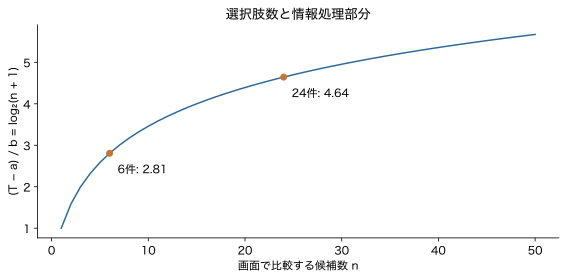

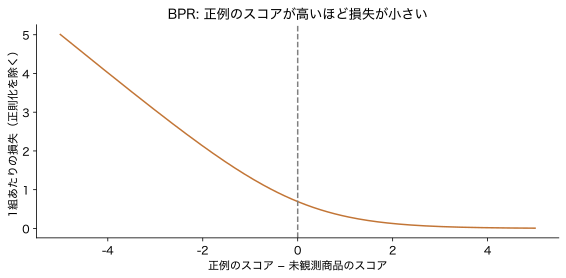

In [10]:
n = np.arange(1, 51)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(n, np.log2(n + 1), color=colors["ALS"])
for count in (6, 24):
    value = np.log2(count + 1)
    ax.scatter(count, value, color=colors["BPR"], zorder=3)
    ax.annotate(f"{count}件: {sig3(value)}", (count, value),
                xytext=(8, -20), textcoords="offset points")
ax.set(title="選択肢数と情報処理部分", xlabel="画面で比較する候補数 n",
       ylabel="(T − a) / b = log₂(n + 1)")
save_svg(fig, "01_choice.svg")

# log(1 + exp(-delta)) を、値が大きい場合にも安定して計算する。
delta = np.linspace(-5, 5, 200)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(delta, np.logaddexp(0, -delta), color=colors["BPR"])
ax.axvline(0, color="gray", linestyle="--")
ax.set(title="BPR: 正例のスコアが高いほど損失が小さい",
       xlabel="正例のスコア − 未観測商品のスコア", ylabel="1組あたりの損失（正則化を除く）")
save_svg(fig, "02_bpr_loss.svg")

本文の5人×10商品の例を、後続の学習と同じSciPyで表す。COO形式は行番号、列番号、値を保持する。顧客ごとに商品を取り出す処理では、行単位のアクセスに適したCSR形式を使う。

array([[0, 1, 0, 0, 1, 0, 0, 0, 0, 0],
       [0, 0, 0, 1, 0, 0, 0, 0, 0, 1],
       [0, 0, 1, 0, 0, 1, 1, 0, 0, 0],
       [0, 0, 0, 1, 0, 0, 0, 0, 0, 0],
       [1, 0, 0, 0, 1, 0, 0, 0, 0, 1]])


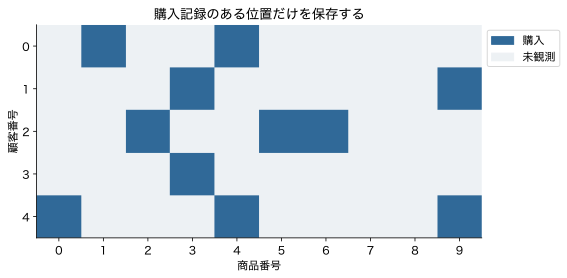

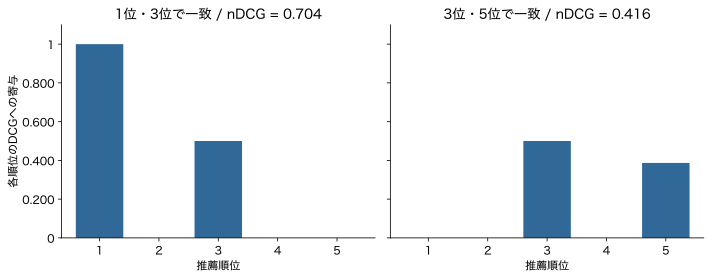

In [11]:
rows = [0, 0, 1, 1, 2, 2, 2, 3, 4, 4, 4]
columns = [1, 4, 3, 9, 2, 5, 6, 3, 0, 4, 9]
small_matrix = sparse.coo_matrix((np.ones(len(rows), dtype=int), (rows, columns)),
                                 shape=(5, 10)).tocsr()
pprint(small_matrix.toarray())

fig, ax = plt.subplots(figsize=(8, 4))
ax.imshow(small_matrix.toarray(), cmap=ListedColormap(["#edf1f4", colors["ALS"]]),
          vmin=0, vmax=1, aspect="auto")
ax.set(xticks=np.arange(10), yticks=np.arange(5), xlabel="商品番号", ylabel="顧客番号",
       title="購入記録のある位置だけを保存する")
ax.legend(handles=[Patch(color=colors["ALS"], label="購入"),
                   Patch(color="#edf1f4", label="未観測")], loc="upper left", bbox_to_anchor=(1, 1))
save_svg(fig, "03_sparse.svg")

# 同じ2件の一致でも、順位によってnDCGが変わることを確認する。
discount = 1 / np.log2(np.arange(2, 7))
ideal = discount[:3].sum()
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, hits, label in zip(axes, ([1, 0, 1, 0, 0], [0, 0, 1, 0, 1]), ("1位・3位で一致", "3位・5位で一致")):
    contributions = np.asarray(hits) * discount
    ax.bar(np.arange(1, 6), contributions, color=colors["ALS"])
    ax.set(title=f"{label} / nDCG = {sig3(contributions.sum() / ideal)}",
           xlabel="推薦順位", xticks=np.arange(1, 6), ylim=(0, 1.10))
axes[0].set_ylabel("各順位のDCGへの寄与")
save_svg(fig, "04_ranking.svg")

### データを整え、学習用とテスト用に分ける

Online Retailは英国の小売業者の取引データである。返品・キャンセル、顧客IDの欠損、送料などを除き、顧客と商品ごとに初回購入だけを残す。本文と同じく、顧客・商品双方に5件以上の購入関係が残るまで絞り込む。

前処理後: 4,074人 × 3,145商品 / 264,510組
{'密度': '0.0206'}


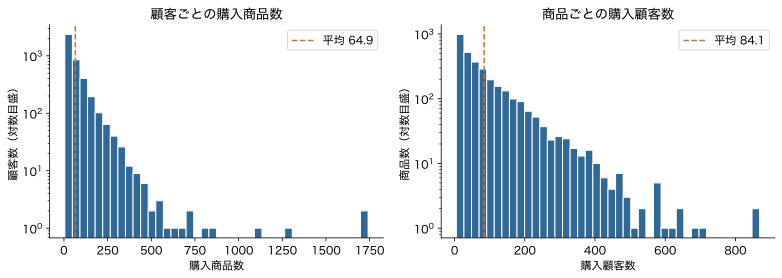

In [12]:
raw = pl.read_csv(data_path, try_parse_dates=True, infer_schema_length=10000)
non_products = ["POST", "M", "C2", "DOT", "BANK CHARGES"]
clean = raw.filter(
    pl.col("CustomerID").is_not_null(),
    pl.col("Quantity") > 0,
    pl.col("UnitPrice") > 0,
    ~pl.col("InvoiceNo").cast(pl.String).str.to_uppercase().str.starts_with("C"),
    ~pl.col("StockCode").cast(pl.String).is_in(non_products),
).unique(maintain_order=True)

# 表示用の商品名を決める。名称は推薦モデルの学習には使わない。
titles = (clean.filter(pl.col("Description").is_not_null())
          .group_by(["StockCode", "Description"]).len()
          .sort(["StockCode", "len", "Description"], descending=[False, True, False])
          .unique("StockCode", keep="first", maintain_order=True)
          .select(pl.col("StockCode").cast(pl.String).alias("item_id"),
                  pl.col("Description").str.strip_chars().alias("title")))

df = (clean.sort("InvoiceDate")
      .unique(["CustomerID", "StockCode"], keep="first", maintain_order=True)
      .select(pl.col("CustomerID").cast(pl.Int64).cast(pl.String).alias("user_id"),
              pl.col("StockCode").cast(pl.String).alias("item_id"),
              pl.col("InvoiceNo").cast(pl.String).alias("invoice_id"),
              pl.col("InvoiceDate").alias("timestamp")))

# 一方を除くと他方の件数も減るため、変化がなくなるまで繰り返す。
while True:
    previous_size = df.height
    for key in ("user_id", "item_id"):
        valid = df.group_by(key).len().filter(pl.col("len") >= 5)[key].to_list()
        df = df.filter(pl.col(key).is_in(valid))
    if df.height == previous_size:
        break
df = df.sort(["user_id", "timestamp", "invoice_id", "item_id"])

user_counts = df.group_by("user_id").len()["len"].to_numpy()
item_counts = df.group_by("item_id").len()["len"].to_numpy()
print(f"前処理後: {len(user_counts):,}人 × {len(item_counts):,}商品 / {df.height:,}組")
pprint({"密度": sig3(df.height / (len(user_counts) * len(item_counts)))})

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, counts, title, xlabel in zip(
    axes, (user_counts, item_counts), ("顧客ごとの購入商品数", "商品ごとの購入顧客数"),
    ("購入商品数", "購入顧客数"),
):
    ax.hist(counts, bins=40, color=colors["ALS"], edgecolor="white")
    ax.axvline(counts.mean(), color=colors["BPR"], linestyle="--",
               label=f"平均 {sig3(counts.mean())}")
    ax.set(title=title, xlabel=xlabel, yscale="log")
    ax.legend()
axes[0].set_ylabel("顧客数（対数目盛）")
axes[1].set_ylabel("商品数（対数目盛）")
save_svg(fig, "05_purchase_distribution.svg")

購入商品数や購入顧客数には偏りがある。次に、顧客ごとに古い取引の約80%を学習用、残りをテスト用にする。同じ伝票の明細は分けない。1取引だけの顧客は学習のみに含め、学習にない商品は評価から除く。この評価は既存顧客・既存商品が対象である。

In [13]:
invoices = (df.group_by(["user_id", "invoice_id"]).agg(pl.col("timestamp").min())
            .sort(["user_id", "timestamp", "invoice_id"])
            .with_columns(pl.int_range(pl.len()).over("user_id").alias("order"),
                          pl.len().over("user_id").alias("count"))
            .with_columns(pl.when(pl.col("count") == 1).then(1)
                          .otherwise((pl.col("count") * 0.800).floor()
                                     .clip(1, pl.col("count") - 1))
                          .cast(pl.Int64).alias("train_end")))
split = df.join(invoices.select("user_id", "invoice_id", "order", "train_end"),
                on=["user_id", "invoice_id"])
train = split.filter(pl.col("order") < pl.col("train_end"))
test = split.filter(pl.col("order") >= pl.col("train_end"))

user_ids = train["user_id"].unique().sort().to_list()
item_ids = train["item_id"].unique().sort().to_list()
user_index = {value: idx for idx, value in enumerate(user_ids)}
item_index = {value: idx for idx, value in enumerate(item_ids)}
before = test.height
test = test.filter(pl.col("item_id").is_in(item_ids))
print(f"学習: {train.height:,}組 / テスト: {test.height:,}組 / 未知商品で除外: {before - test.height}組")

def interaction_matrix(frame):
    indexed = frame.with_columns(
        pl.col("user_id").replace_strict(user_index, return_dtype=pl.Int32).alias("u"),
        pl.col("item_id").replace_strict(item_index, return_dtype=pl.Int32).alias("i"),
    )
    return sparse.csr_matrix(
        (np.ones(indexed.height, dtype=np.float32), (indexed["u"].to_numpy(), indexed["i"].to_numpy())),
        shape=(len(user_ids), len(item_ids)),
    )

train_matrix = interaction_matrix(train)
test_matrix = interaction_matrix(test)
pprint({"行列サイズ": train_matrix.shape, "学習の非ゼロ要素": train_matrix.nnz,
        "テストの非ゼロ要素": test_matrix.nnz})

学習: 210,600組 / テスト: 53,894組 / 未知商品で除外: 16組
{'テストの非ゼロ要素': 53894, '学習の非ゼロ要素': 210600, '行列サイズ': (4074, 3143)}


### ALSとBPRを学習し、未購入商品の上位5件を出す

潜在因子は64次元、乱数シードは42とする。本文に合わせ、ALSの誤差の重みは購入・未観測とも1にする。BPRは保存された購入位置を正例として扱う。モデル間ではスコアの尺度が異なるため、値の大小を直接比較しない。

In [14]:
# BLASとモデルのスレッド数を固定し、実行条件をそろえる。
with threadpool_limits(limits=1, user_api="blas"):
    models = {
        "ALS": AlternatingLeastSquares(factors=64, regularization=0.0100, alpha=1.00,
                                       iterations=30, random_state=42, num_threads=1,
                                       use_gpu=False),
        "BPR": BayesianPersonalizedRanking(factors=64, learning_rate=0.0500,
                                          regularization=0.0100, iterations=100,
                                          random_state=42, num_threads=1, use_gpu=False),
    }
    for name, model in models.items():
        model.fit(train_matrix, show_progress=False)
        print(f"{name}: 学習完了")

target_user = "12347"
u = user_index[target_user]
top_k = 5
print(f"対象顧客: {target_user} / 学習期間の購入商品数: {train_matrix[u].nnz}")

# ALSの内積から全商品のスコアを計算し、購入済みを除く。
scores = models["ALS"].item_factors @ models["ALS"].user_factors[u]
scores[train_matrix[u].indices] = -np.inf
top_ids = np.argsort(-scores)[:top_k]
pprint({"ALSの上位商品ID": [item_ids[i] for i in top_ids],
        "スコア": [sig3(scores[i]) for i in top_ids]})

ALS: 学習完了


BPR: 学習完了
対象顧客: 12347 / 学習期間の購入商品数: 82
{'ALSの上位商品ID': ['22697', '22698', '21212', '22730', '21977'],
 'スコア': ['0.805', '0.715', '0.590', '0.587', '0.432']}


shape: (10, 5)
┌────────┬──────┬────────┬────────────────────────────────────┬────────┐
│ モデル ┆ 順位 ┆ 商品ID ┆ 商品名                             ┆ スコア │
│ ---    ┆ ---  ┆ ---    ┆ ---                                ┆ ---    │
│ str    ┆ i64  ┆ str    ┆ str                                ┆ str    │
╞════════╪══════╪════════╪════════════════════════════════════╪════════╡
│ ALS    ┆ 1    ┆ 22697  ┆ GREEN REGENCY TEACUP AND SAUCER    ┆ 0.805  │
│ ALS    ┆ 2    ┆ 22698  ┆ PINK REGENCY TEACUP AND SAUCER     ┆ 0.715  │
│ ALS    ┆ 3    ┆ 21212  ┆ PACK OF 72 RETROSPOT CAKE CASES    ┆ 0.590  │
│ ALS    ┆ 4    ┆ 22730  ┆ ALARM CLOCK BAKELIKE IVORY         ┆ 0.587  │
│ ALS    ┆ 5    ┆ 21977  ┆ PACK OF 60 PINK PAISLEY CAKE CASES ┆ 0.432  │
│ BPR    ┆ 1    ┆ 20963  ┆ APPLE BATH SPONGE                  ┆ 3.85   │
│ BPR    ┆ 2    ┆ 79144B ┆ PAINTED LIGHTBULB STAR+ MOON       ┆ 3.76   │
│ BPR    ┆ 3    ┆ 22471  ┆ TV DINNER TRAY AIR HOSTESS         ┆ 3.75   │
│ BPR    ┆ 4    ┆ 47341B ┆ BLUE TABLE RUN FLOWER 

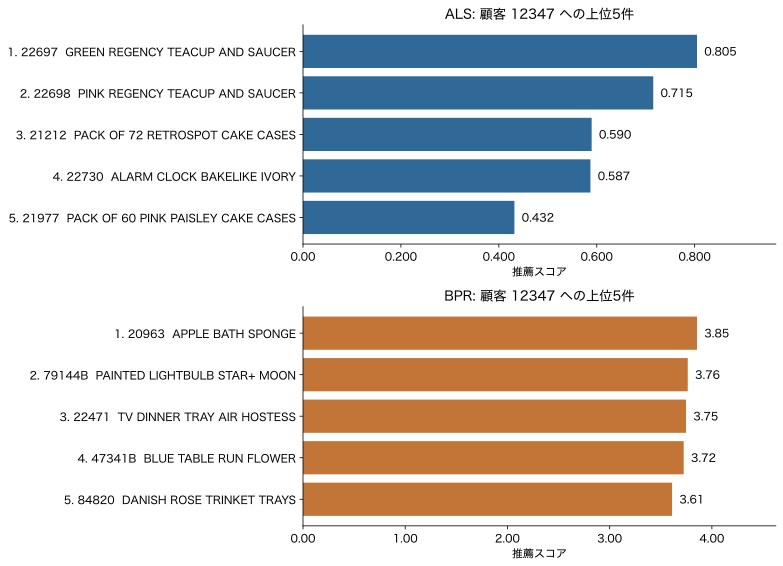

In [15]:
title_lookup = dict(titles.iter_rows())
target_recommendations = {}
table_rows = []
fig, axes = plt.subplots(2, 1, figsize=(11, 8))

for ax, (name, model) in zip(axes, models.items()):
    ids, values = model.recommend(u, train_matrix[u], N=top_k,
                                  filter_already_liked_items=True)
    target_recommendations[name] = ids
    labels = []
    for rank, (item, value) in enumerate(zip(ids, values), start=1):
        item_id = item_ids[int(item)]
        title = title_lookup.get(item_id, item_id)
        labels.append(f"{rank}. {item_id}  {title}")
        table_rows.append({"モデル": name, "順位": rank, "商品ID": item_id,
                           "商品名": title, "スコア": sig3(value)})
    positions = np.arange(top_k)
    ax.barh(positions, values, color=colors[name])
    ax.set_yticks(positions, labels)
    ax.invert_yaxis()
    ax.set(title=f"{name}: 顧客 {target_user} への上位5件", xlabel="推薦スコア")
    ax.set_xlim(0, float(values.max()) * 1.20)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda value, position: sig3(value)))
    for position, value in zip(positions, values):
        ax.text(value, position, f"  {sig3(value)}", va="center")

print(pl.DataFrame(table_rows))
# カテゴリ名を設定した軸は数値の目盛り形式を変更しない。
fig.tight_layout()
fig.savefig(image_dir / "06_recommendations.svg", format="svg", bbox_inches="tight")
plt.close(fig)
display(SVG(filename=str(image_dir / "06_recommendations.svg")))

### テスト期間の購入と比較する

全顧客の推薦を作り、Precision@5、Recall@5、nDCG@5を計算する。未購入商品の候補全体から順位を付け、テストの購入情報は推薦候補の除外に使わない。

{'Precision@5': '0.0871',
 'Recall@5': '0.0389',
 'nDCG@5': '0.0979',
 'モデル': 'ALS',
 '評価顧客数': 2716}
{'Precision@5': '0.0484',
 'Recall@5': '0.0267',
 'nDCG@5': '0.0555',
 'モデル': 'BPR',
 '評価顧客数': 2716}


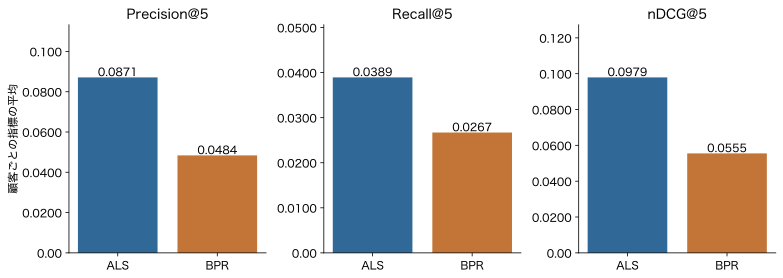

検証完了: 分割、購入済み商品の除外、指標の範囲を確認した。


In [16]:
def evaluate_at_k(recommendations, truth):
    per_user = []
    discount = 1 / np.log2(np.arange(2, top_k + 2))
    for user, recommended in enumerate(recommendations):
        relevant = truth[user].indices
        if len(relevant) == 0:
            continue
        hits = np.isin(recommended, relevant).astype(int)
        dcg = np.dot(hits, discount)
        idcg = discount[:min(len(relevant), top_k)].sum()
        per_user.append([hits.sum() / top_k, hits.sum() / len(relevant), dcg / idcg])
    values = np.asarray(per_user)
    return values.mean(axis=0), len(per_user)

all_recommendations = {}
metric_values = {}
metric_names = ["Precision@5", "Recall@5", "nDCG@5"]

with threadpool_limits(limits=1, user_api="blas"):
    for name, model in models.items():
        # 顧客を配列で渡すと、全員分の候補をまとめて取得できる。
        ids, _ = model.recommend(np.arange(len(user_ids)), train_matrix, N=top_k,
                                  filter_already_liked_items=True)
        all_recommendations[name] = ids
        metrics, n_evaluated = evaluate_at_k(ids, test_matrix)
        metric_values[name] = metrics
        pprint({"モデル": name, "評価顧客数": n_evaluated,
                **dict(zip(metric_names, map(sig3, metrics)))})

fig, axes = plt.subplots(1, 3, figsize=(11, 4))
for metric_idx, (ax, metric_name) in enumerate(zip(axes, metric_names)):
    values = [metric_values[name][metric_idx] for name in models]
    bars = ax.bar(np.arange(2), values, color=list(colors.values()))
    ax.set_xticks(np.arange(2), list(models))
    ax.set(title=metric_name, ylim=(0, max(values) * 1.30))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, position: sig3(value)))
    for bar, value in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, value, sig3(value), ha="center", va="bottom")
axes[0].set_ylabel("顧客ごとの指標の平均")
fig.tight_layout()
fig.savefig(image_dir / "07_metrics.svg", format="svg", bbox_inches="tight")
plt.close(fig)
display(SVG(filename=str(image_dir / "07_metrics.svg")))

# 評価の前提を確認する。購入ペアや同一伝票が学習とテストにまたがらない。
assert train_matrix.multiply(test_matrix).nnz == 0
assert set(train.select("user_id", "invoice_id").iter_rows()).isdisjoint(
    test.select("user_id", "invoice_id").iter_rows()
)
for name, recommendations in all_recommendations.items():
    assert recommendations.shape == (len(user_ids), top_k)
    assert ((recommendations >= 0) & (recommendations < len(item_ids))).all()
    assert all(len(set(row)) == top_k for row in recommendations)
    assert all(not np.isin(recommendations[user], train_matrix[user].indices).any()
               for user in range(len(user_ids)))
    assert np.isfinite(metric_values[name]).all()
    assert ((metric_values[name] >= 0) & (metric_values[name] <= 1)).all()
assert np.array_equal(top_ids, target_recommendations["ALS"])
print("検証完了: 分割、購入済み商品の除外、指標の範囲を確認した。")

今回の分割と設定ではALSが3指標ともBPRを上回った。これだけでALSが常に優れるとは言えない。設定を検証用データで選び、別の期間でも確かめる必要がある。

なお、本文に合わせた対象の絞り込みには全期間の履歴を使っている。また、顧客ごとに分割時点が異なる。厳密な将来予測の検証では、全体で基準日を固定し、対象の選定もその日以前の情報だけで行う。

## 結論

この記事では、購入履歴を行列分解で推薦順位に変え、ALSとBPRの結果を過去データで評価する手順を紹介した。

次の判断は、候補となったモデルを現行の推薦と比較することである。過去の購入を当てられても、売上が増えるとは限らない。A/Bテストでクリック率や購買転換率を調べ、多様性やカバレッジも確認する。

2026年11月30日発売予定の[『マーケティングサイエンスの理論と実践』](https://gihyo.jp/book/2026/978-4-297-16025-8)では、こうした課題、理論、実装、施策への判断を順に扱う。第11章では評価指標の使い分けも説明し、次章ではグラフを使った推薦へ進む。[サポートページ](https://github.com/gihyo-book/marketing_science_book)でコードを確認できる。

参考データ：Daqing Chen, *Online Retail*（2015）, [UCI / DOI: 10.24432/C5BW33](https://doi.org/10.24432/C5BW33), [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/)。本記事ではCSVに変換されたデータに、上記の抽出・重複除去を行った。実装の仕様は[implicitのALSドキュメント](https://benfred.github.io/implicit/api/models/cpu/als.html)も参照した。